# A six-state geodesic combing of $(D_\infty\times D_\infty)*C_2$

We use the right-angled Coxeter group
$$W=\langle a,b,c,d,e\mid a^2=b^2=c^2=d^2=e^2=1,\quad [a,c]=[a,d]=[b,c]=[b,d]=1\rangle.$$
There are no further relations. Its standard generators are all involutions. Set
$$H=\langle a,b,c,d\rangle=\langle a,b\rangle\times\langle c,d\rangle\cong D_\infty\times D_\infty,$$
so $W=H*\langle e\rangle\cong(D_\infty\times D_\infty)*C_2$.

The subgroup $H$ contains $\langle ab,cd\rangle\cong\mathbb Z^2$ with index $4$. Thus $H$ is **virtually abelian**, and $W$ is hyperbolic relative to $H$. It is not word-hyperbolic because it contains $\mathbb Z^2$.

This notebook mirrors the $\mathbb Z*\mathbb Z^2$ example: a labeled combing and its quotient graph, exact Perron–Frobenius data, Cayley and coned-off pictures, and ordered-frequency experiments. We use the shortlex order $a<b<c<d<e$.

The defining graph is triangle-free, so this is a two-dimensional Coxeter system. A geodesic biautomatic structure over the standard generators exists by [Munro–Osajda–Przytycki, Theorem 1.1](https://www.math.uni.wroc.pl/~dosaj/trav/Coxeter_biautomatic.pdf), supplying the manuscript's admissible-generating-set hypothesis. Our chosen combing is the explicit shortlex language below; it need not be identified with that paper's standard language.

Run the cells in order. Dependencies: `numpy`, `networkx`, `sympy`, `matplotlib`, and `IPython`. Defaults: radius-5 finite checks, radius-3 Cayley pictures, and 100,000 sampled letters. Every figure is saved as a PNG beside this notebook.


In [1]:
import itertools
import math
from collections import deque
from functools import lru_cache
import heapq
import numpy as np
import networkx as nx
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, Circle
from matplotlib.lines import Line2D
from IPython.display import display, Math, Markdown

plt.ioff()
plt.rcParams.update({'figure.dpi': 120, 'font.size': 11})
np.set_printoptions(linewidth=140)

### The defining graph and peripheral subgroup

Edges in the right-angled defining graph mean **commutation**. The four vertices $a,c,b,d$ form a square; $e$ is isolated. Opposite corners of the square generate the two infinite dihedral factors of $H$. A disconnected defining graph gives a free product in this convention. This defining graph is distinct from the combing automaton below.

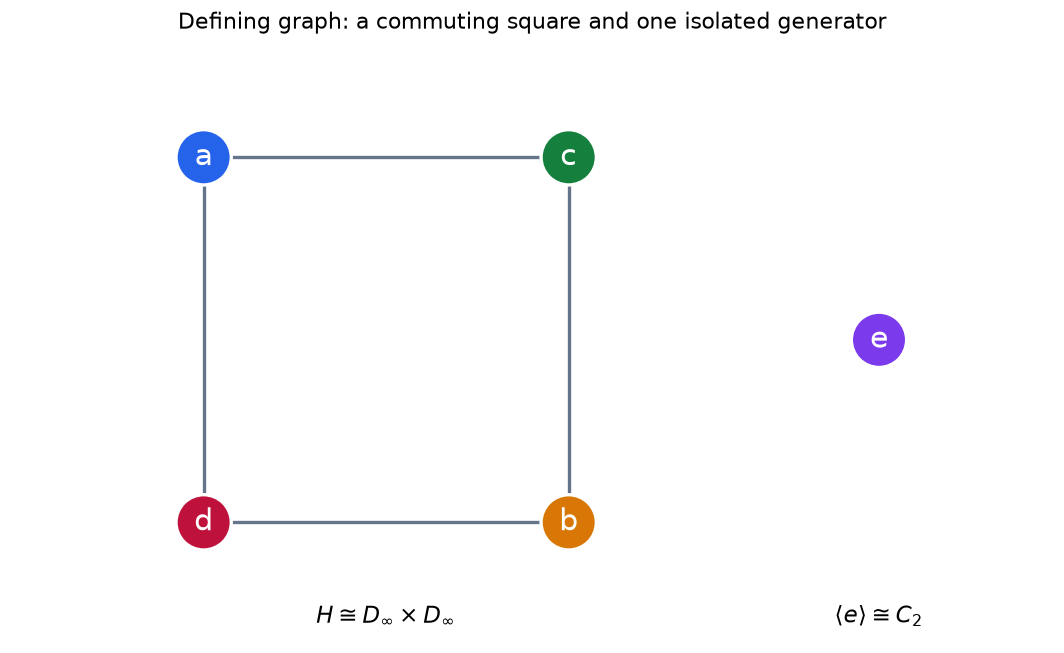

In [2]:
letters = tuple('abcde')
commutes = {'a': {'c','d'}, 'b': {'c','d'}, 'c': {'a','b'}, 'd': {'a','b'}, 'e': set()}
letter_tex = {s: s for s in letters}
palette = {'a':'#2563eb', 'b':'#d97706', 'c':'#15803d', 'd':'#be123c', 'e':'#7c3aed'}
H_letters = frozenset('abcd')
peripheral_generators = {'H': H_letters}
defining_graph = nx.Graph()
defining_graph.add_nodes_from(letters)
defining_graph.add_edges_from((s,t) for s in letters for t in commutes[s] if s < t)
assert defining_graph.number_of_edges() == 4
assert nx.is_isomorphic(defining_graph.subgraph(H_letters), nx.cycle_graph(4))
assert defining_graph.degree('e') == 0

defining_pos = {'a':(-1,1), 'c':(1,1), 'b':(1,-1), 'd':(-1,-1), 'e':(2.7,0)}
fig_defining, ax_defining = plt.subplots(figsize=(9,5.5))
nx.draw_networkx_edges(defining_graph, defining_pos, ax=ax_defining, width=2, edge_color='#64748b')
nx.draw_networkx_nodes(defining_graph, defining_pos, ax=ax_defining, node_size=1100,
    node_color=[palette[s] for s in letters], edgecolors='white', linewidths=2)
nx.draw_networkx_labels(defining_graph, defining_pos, ax=ax_defining, font_color='white',font_size=18)
ax_defining.text(0,-1.55,r'$H\cong D_\infty\times D_\infty$',ha='center',fontsize=14)
ax_defining.text(2.7,-1.55,r'$\langle e\rangle\cong C_2$',ha='center',fontsize=14)
ax_defining.set_title('Defining graph: a commuting square and one isolated generator')
ax_defining.set_aspect('equal'); ax_defining.margins(0.25); ax_defining.axis('off')
fig_defining.tight_layout()
fig_defining.savefig('simple_coxeter_defining_graph.png',dpi=300,bbox_inches='tight')
plt.show()

## 1. States and labeled transitions

Each element of $H$ has a unique representative $xy$, where $x$ is an alternating word in $a,b$ and $y$ is an alternating word in $c,d$; either may be empty. We write every $H$ syllable in this order. In the free product $H*C_2$, nonempty $H$ syllables alternate with single letters $e$. The empty word represents the identity.

The state records the last letter read. The six states are $v_0,v_a,v_b,v_c,v_d,v_e$. Every state is accepting, and an allowed letter $s$ leads to $v_s$.

| State | Allowed next letters |
|:--|:--|
| $v_0$ | $a,b,c,d,e$ |
| $v_a$ | $b,c,d,e$ |
| $v_b$ | $a,c,d,e$ |
| $v_c$ | $d,e$ |
| $v_d$ | $c,e$ |
| $v_e$ | $a,b,c,d$ |

There are 21 transitions. No self-loops occur, because every generator is an involution. After entering the $c,d$ part of an $H$ syllable, one cannot return to its $a,b$ part until an $e$ starts a new syllable.

In [3]:
states = ['v0']+['v_'+s for s in letters]
idx = {state:i for i,state in enumerate(states)}
state_tex = {'v0':r'v_0', **{'v_'+s:'v_{'+s+'}' for s in letters}}
allowed = {'v0':'abcde','v_a':'bcde','v_b':'acde','v_c':'de','v_d':'ce','v_e':'abcd'}
transitions = {state:[(s,'v_'+s) for s in row] for state,row in allowed.items()}
G = nx.MultiDiGraph()
G.add_nodes_from(states)
for source,outgoing in transitions.items():
    for s,target in outgoing: G.add_edge(source,target,key=s,label=s)
assert len(states) == 6 and G.number_of_edges() == 21
assert G.in_degree('v0') == 0 and nx.number_of_selfloops(G) == 0
print(f'{len(states)} accepting states and {G.number_of_edges()} labeled transitions.')

6 accepting states and 21 labeled transitions.


## 2. The directed graph $\mathcal G$

The initial state $v_0$ is centered; the five other states lie on a circle. Every arrow carries its input letter, also identified by color. The initial arrows are straight, and paired noninitial arrows curve apart. Double circles mark accepting states.

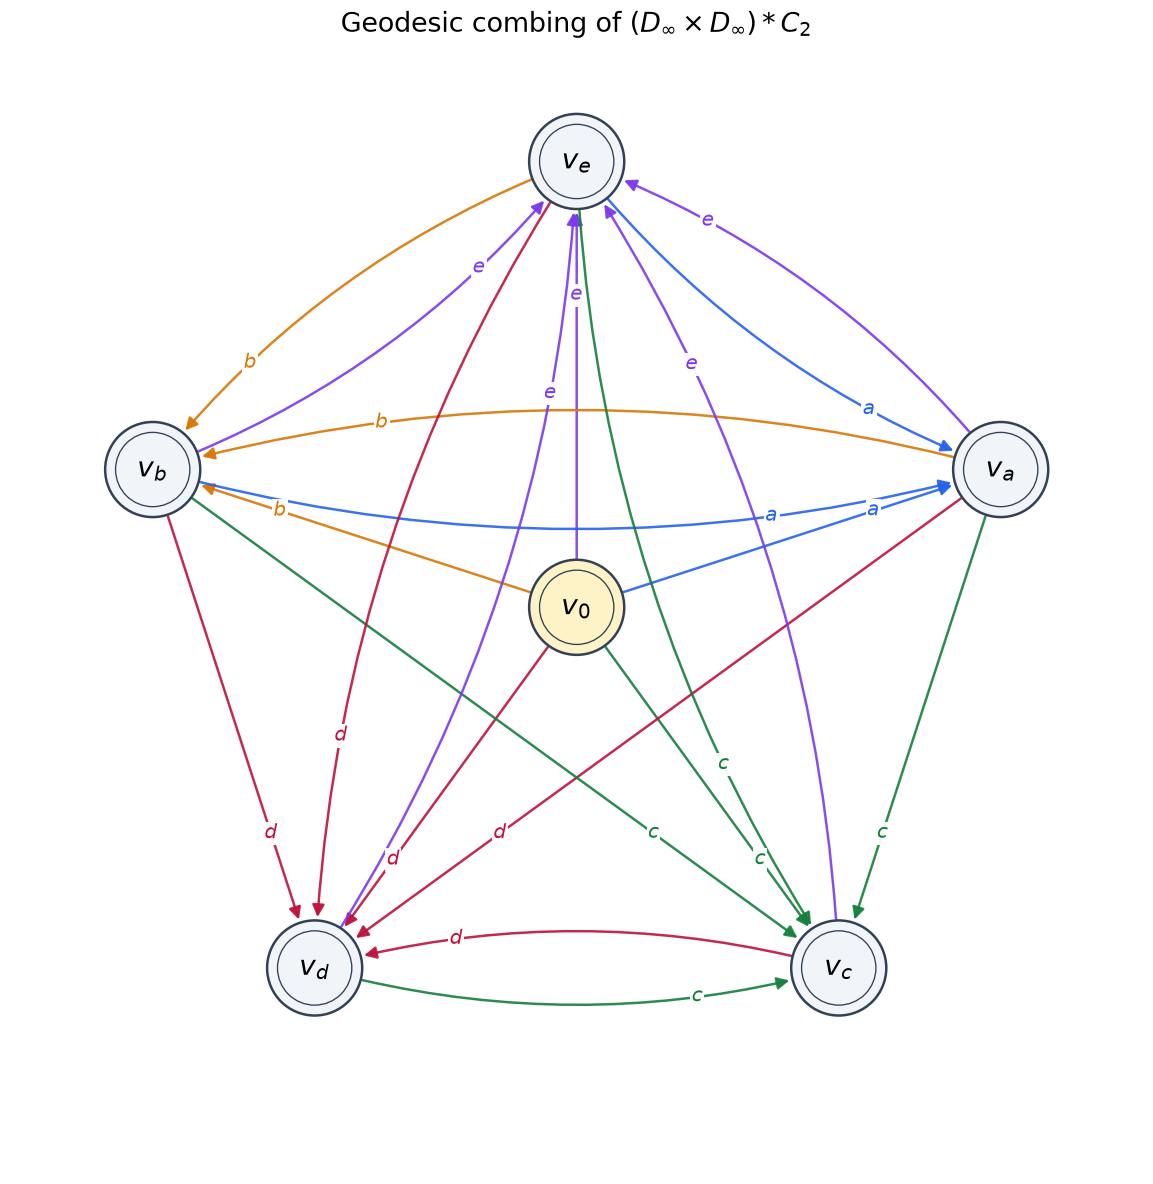

In [4]:
automaton_pos = {'v0': np.array([0.0,0.0])}
outer_order = ['v_e','v_a','v_c','v_d','v_b']
for j,state in enumerate(outer_order):
    theta = np.pi/2-2*np.pi*j/len(outer_order)
    automaton_pos[state] = 1.5*np.array([np.cos(theta),np.sin(theta)])
node_radius = 0.16
fig_automaton,ax_automaton = plt.subplots(figsize=(10,10))
for source,target,data in G.edges(data=True):
    s = data['label']; p = automaton_pos[source]; q = automaton_pos[target]
    rad = 0.14 if G.has_edge(target,source) else 0.0
    if source == 'v0': rad = 0.0
    edge = FancyArrowPatch(p,q,connectionstyle=f'arc3,rad={rad}',arrowstyle='-|>',
        mutation_scale=15,lw=1.5,color=palette[s],alpha=0.9,
        patchA=Circle(p,node_radius,transform=ax_automaton.transData),
        patchB=Circle(q,node_radius,transform=ax_automaton.transData),shrinkA=1,shrinkB=2,zorder=1)
    ax_automaton.add_patch(edge)
    delta = q-p
    control = (p+q)/2+rad*np.array([delta[1],-delta[0]])
    t = 0.70 if source == 'v0' else 0.73
    label_pos = (1-t)**2*p+2*(1-t)*t*control+t*t*q
    ax_automaton.text(*label_pos,'$'+s+'$',ha='center',va='center',fontsize=12,
        color=palette[s],bbox=dict(fc='white',ec='none',pad=0.8,alpha=0.95),zorder=3)
for state,point in automaton_pos.items():
    facecolor = '#fef3c7' if state == 'v0' else '#f1f5f9'
    ax_automaton.add_patch(Circle(point,node_radius,fc=facecolor,ec='#334155',lw=1.5,zorder=4))
    ax_automaton.add_patch(Circle(point,node_radius-0.035,fill=False,ec='#334155',lw=0.8,zorder=5))
    ax_automaton.text(*point,'$'+state_tex[state]+'$',ha='center',va='center',fontsize=17,zorder=6)
ax_automaton.set_title(r'Geodesic combing of $(D_\infty\times D_\infty)*C_2$',fontsize=16)
ax_automaton.set(xlim=(-1.9,1.9),ylim=(-1.9,1.9),aspect='equal')
ax_automaton.axis('off'); fig_automaton.tight_layout()
fig_automaton.savefig('simple_coxeter_automaton.png',dpi=300,bbox_inches='tight')
plt.show()

## 3. Adjacency matrix and growth

Use the state order $(v_0,v_a,v_b,v_c,v_d,v_e)$. An entry $M_{ij}$ counts labeled edges from state $i$ to state $j$; all entries here are $0$ or $1$, and the initial column is zero. This is the adjacency matrix, not the stochastic Markov matrix $N$.

The growth series is
$$\sum_{n\ge0}|S_n(W,S)|t^n=\frac{(1+t)^2}{1-3t}.$$
Hence $|S_0|=1$, $|S_1|=5$, and $|S_n|=16\cdot3^{n-2}$ for $n\ge2$. The exponential growth rate is $\lambda=3$.

In [5]:
M = nx.to_numpy_array(G,nodelist=states,dtype=int,weight=None)
M_exact = sp.Matrix(M)
expected_M = sp.Matrix([
    [0,1,1,1,1,1],
    [0,0,1,1,1,1],
    [0,1,0,1,1,1],
    [0,0,0,0,1,1],
    [0,0,0,1,0,1],
    [0,1,1,1,1,0]])
assert M_exact == expected_M
pf_spectrum = M_exact.eigenvals()
assert pf_spectrum == {sp.Integer(3):1,sp.Integer(-1):3,sp.Integer(0):2}
display(Math(r'\text{State order: }('+','.join(state_tex[s] for s in states)+')'))
display(Math(r'M='+sp.latex(M_exact)))
x,t = sp.symbols('x t')
display(Math(r'\chi_M(x)='+sp.latex(sp.factor(M_exact.charpoly(x).as_expr()))))
display(Math(r'\operatorname{spec}(M)=\{3^{(1)},(-1)^{(3)},0^{(2)}\}'))
transfer_growth = sp.factor((sp.eye(len(states))-t*M_exact).inv()[0,:].dot(sp.ones(len(states),1)))
assert sp.cancel(transfer_growth-(1+t)**2/(1-3*t)) == 0
display(Math(r'\mathbf e_0^T(I-tM)^{-1}\mathbf1='+sp.latex(transfer_growth)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### Exact Perron–Frobenius data and the vertex measure

Use the manuscript's Cesàro normalization, as in the $\mathbb Z*\mathbb Z^2$ notebook:
$$r=\lim_{n\to\infty}\frac1n\sum_{k=0}^{n}\lambda^{-k}M^k\mathbf1,
\qquad \ell=\lim_{n\to\infty}\frac1n\sum_{k=0}^{n}\lambda^{-k}(M^T)^k\mathbf e_0.$$
The eigenvalue $3$ is simple and strictly dominant. Thus its exact spectral projection is $P=u v^T/(v^Tu)$, and $r=P\mathbf1$, $\ell=P^T\mathbf e_0$. Their scaling is fixed by these formulas.

Set $N_{ij}=M_{ij}r_j/(\lambda r_i)$ when $r_i>0$, with an identity row when $r_i=0$, and set $\mu_i=r_i\ell_i/\sum_jr_j\ell_j$. The stationary vertex measure $\mu$ is distinct from the based path law beginning at $v_0$.

In [6]:
num_states = len(states)
I = sp.eye(num_states)
ones = sp.ones(num_states, 1)
e0 = I[:, idx['v0']]
lam = sp.Integer(3)
assert pf_spectrum[lam] == 1 and all(abs(value) < lam for value in pf_spectrum if value != lam)
u = (M_exact-lam*I).nullspace()[0]
v = (M_exact.T-lam*I).nullspace()[0]
P = (u*v.T/v.dot(u)).applyfunc(sp.simplify)
r = (P*ones).applyfunc(sp.simplify)
l = (P.T*e0).applyfunc(sp.simplify)
N = sp.Matrix(num_states, num_states,
    lambda i, j: sp.simplify(M_exact[i,j]*r[j]/(lam*r[i])) if r[i] != 0 else sp.Integer(i == j))
mu_weights = r.multiply_elementwise(l)
mu = (mu_weights/sum(mu_weights)).applyfunc(sp.simplify)
assert P*P == P
assert M_exact*r == lam*r and M_exact.T*l == lam*l
assert N*ones == ones and N.T*mu == mu and sum(mu) == 1
assert all(value >= 0 for value in r) and all(value >= 0 for value in l)
assert all(value >= 0 for value in N) and all(value >= 0 for value in mu)
assert mu[idx['v0']] == 0

display(Math(r'\lambda='+sp.latex(lam)))
display(Math(r'r='+sp.latex(r)+r'\qquad\ell='+sp.latex(l)))
display(Math(r'\mu='+sp.latex(mu)))
rows = [r'| State | $r_i$ | $\ell_i$ | $\mu_i$ |', '|:--|--:|--:|--:|']
for state in states:
    i = idx[state]
    rows.append('| $'+state_tex[state]+'$ | $'+sp.latex(r[i])+'$ | $'+sp.latex(l[i])+'$ | $'+sp.latex(mu[i])+'$ |')
display(Markdown('\n'.join(rows)))
display(Math(r'N='+sp.latex(N)))
print('Exact checks passed: projection, PF equations, nonnegativity, stochasticity, and stationarity.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

| State | $r_i$ | $\ell_i$ | $\mu_i$ |
|:--|--:|--:|--:|
| $v_0$ | $\frac{16}{9}$ | $0$ | $0$ |
| $v_{a}$ | $\frac{4}{3}$ | $\frac{2}{9}$ | $\frac{1}{6}$ |
| $v_{b}$ | $\frac{4}{3}$ | $\frac{2}{9}$ | $\frac{1}{6}$ |
| $v_{c}$ | $\frac{2}{3}$ | $\frac{4}{9}$ | $\frac{1}{6}$ |
| $v_{d}$ | $\frac{2}{3}$ | $\frac{4}{9}$ | $\frac{1}{6}$ |
| $v_{e}$ | $\frac{4}{3}$ | $\frac{4}{9}$ | $\frac{1}{3}$ |

<IPython.core.display.Math object>

Exact checks passed: projection, PF equations, nonnegativity, stochasticity, and stationarity.


## 4. Component quotient and maximal component

The two strongly connected components are $C_0=\{v_0\}$ and $C_1=\{v_a,v_b,v_c,v_d,v_e\}$. The component quotient has one arrow $C_0\to C_1$; internal edges are suppressed. The noninitial component is terminal and maximal.

This component is aperiodic: $v_a\to v_b\to v_a$ is a two-cycle, and $v_a\to v_c\to v_e\to v_a$ is a three-cycle. The Cayley graph is bipartite, but the automaton forgets the parity of word length. Thus the finite-state Markov chain on $C_1$ is mixing, including when sampled every $k$ steps.

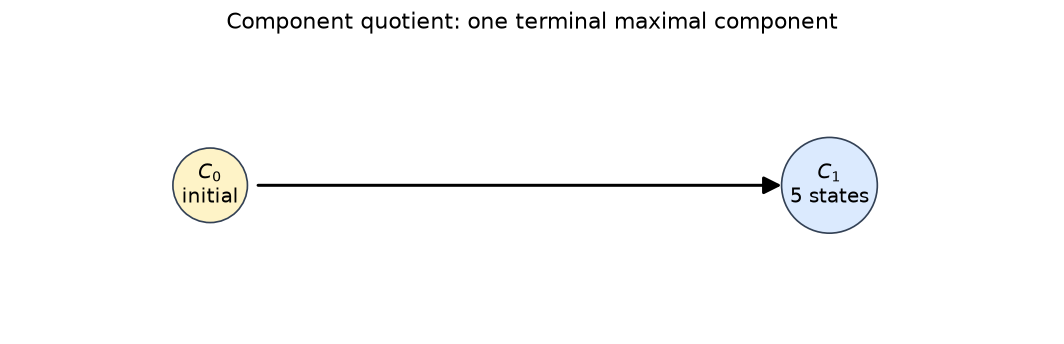

In [7]:
components = sorted(nx.strongly_connected_components(G),key=lambda comp:min(idx[s] for s in comp))
assert components == [{'v0'},set(states[1:])]
component_of = {s:i for i,comp in enumerate(components) for s in comp}
quotient = nx.DiGraph(); quotient.add_nodes_from(range(len(components)))
for u,v in G.edges():
    if component_of[u] != component_of[v]: quotient.add_edge(component_of[u],component_of[v])
assert set(quotient.edges()) == {(0,1)}
component_C = components[1]
assert nx.is_aperiodic(nx.DiGraph(G.subgraph(component_C)))
for cycle in [('v_a','v_b','v_a'),('v_a','v_c','v_e','v_a')]:
    assert all(G.has_edge(u,v) for u,v in zip(cycle,cycle[1:]))

fig_quotient,ax_quotient = plt.subplots(figsize=(9,3))
quotient_pos = {0:(0,0),1:(2.5,0)}
nx.draw_networkx_nodes(quotient,quotient_pos,ax=ax_quotient,node_size=[2000,3300],
    node_color=['#fef3c7','#dbeafe'],edgecolors='#334155')
nx.draw_networkx_edges(quotient,quotient_pos,ax=ax_quotient,arrows=True,arrowstyle='-|>',
    arrowsize=22,node_size=3300,width=1.8)
nx.draw_networkx_labels(quotient,quotient_pos,ax=ax_quotient,
    labels={0:'$C_0$\ninitial',1:'$C_1$\n5 states'},font_size=12)
ax_quotient.set_xlim(-0.8,3.4);ax_quotient.set_ylim(-0.55,0.55);ax_quotient.axis('off')
ax_quotient.set_title('Component quotient: one terminal maximal component')
fig_quotient.tight_layout()
fig_quotient.savefig('simple_coxeter_component_quotient.png',dpi=300,bbox_inches='tight')
plt.show()

### Exact data on $C=C_1$

Let $M_C$ be the $5\times5$ principal submatrix in the inherited order $(v_a,v_b,v_c,v_d,v_e)$. Compute $\lambda_C=3$, the spectral projection $P_C$, and $r_C=P_C\mathbf1_C$. Then
$$(N_C)_{ij}=\frac{(M_C)_{ij}(r_C)_j}{\lambda_C(r_C)_i}.$$
Since $C$ is terminal, $r_C$ is the restriction of $r$, and $N_C$ is the restriction of $N$.

In [8]:
states_C = [state for state in states if state in component_C]
indices_C = [idx[s] for s in states_C]
M_C = M_exact.extract(indices_C, indices_C)
spectrum_C = M_C.eigenvals()
lam_C = max(spectrum_C)
assert lam_C == lam and spectrum_C[lam_C] == 1
size_C = len(states_C)
u_C = (M_C-lam_C*sp.eye(size_C)).nullspace()[0]
v_C = (M_C.T-lam_C*sp.eye(size_C)).nullspace()[0]
P_C = (u_C*v_C.T/v_C.dot(u_C)).applyfunc(sp.simplify)
r_C = (P_C*sp.ones(size_C,1)).applyfunc(sp.simplify)
N_C = sp.Matrix(size_C,size_C, lambda i,j: sp.simplify(M_C[i,j]*r_C[j]/(lam_C*r_C[i])))
mu_C = mu.extract(indices_C,[0])
assert M_C*r_C == lam_C*r_C
assert r_C == r.extract(indices_C,[0])
assert N_C == N.extract(indices_C,indices_C)
assert N_C*sp.ones(size_C,1) == sp.ones(size_C,1)
assert N_C.T*mu_C == mu_C and sum(mu_C) == 1
assert all(value > 0 for value in r_C)
display(Math(r'\lambda_C='+sp.latex(lam_C)))
display(Math(r'M_C='+sp.latex(M_C)))
display(Math(r'N_C='+sp.latex(N_C)))
print('Exact component checks passed; C is terminal, irreducible, and aperiodic.')

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Exact component checks passed; C is terminal, irreducible, and aperiodic.


## 5. Why this is a geodesic combing

In $D_\infty=C_2*C_2$, reduced representatives are precisely the alternating words in the two involutions, including the empty word. The direct product $H=\langle a,b\rangle\times\langle c,d\rangle$ therefore has unique normal forms $xy$, with $x$ alternating in $a,b$ and $y$ alternating in $c,d$. The word metric from $a,b,c,d$ is the sum of the two factor lengths, so $xy$ is geodesic.

The free-product normal form in $H*\langle e\rangle$ is a unique alternating sequence of nonidentity $H$ syllables and letters $e$. Concatenating the chosen representatives for the $H$ syllables gives a unique geodesic word in $W$. The displayed transitions recognize exactly these words. Every prefix has the same form, so the accepted language is prefix-closed. The ordering $a<b<c<d<e$ makes this the shortlex normal form.

For a finite check independent of the six-state transition table, we use the standard right-angled Coxeter reduction: cancel equal letters separated only by commuting letters, then lexicographically sort the remaining dependence graph. The next cell compares breadth-first search in the group with accepted paths through radius five. The subsequent cell independently repeats the check using a faithful integer-matrix representation.

In [9]:
@lru_cache(maxsize=200000)
def _canonical_tuple(word):
    # Cancel equal letters when every intervening letter commutes with them.
    reduced = []
    for s in word:
        for j in range(len(reduced)-1, -1, -1):
            t = reduced[j]
            if t == s:
                reduced.pop(j)
                break
            if t not in commutes[s]:
                reduced.append(s)
                break
        else:
            reduced.append(s)
    # Noncommuting occurrences retain their order. A greedy topological sort
    # chooses the lexicographically least representative of this reduced trace.
    successors = [[] for _ in reduced]
    indegree = [0]*len(reduced)
    for i, s in enumerate(reduced):
        for j in range(i+1,len(reduced)):
            if reduced[j] not in commutes[s]:
                successors[i].append(j)
                indegree[j] += 1
    ready = [(reduced[i],i) for i,d in enumerate(indegree) if d == 0]
    heapq.heapify(ready)
    normal = []
    while ready:
        s,i = heapq.heappop(ready)
        normal.append(s)
        for j in successors[i]:
            indegree[j] -= 1
            if indegree[j] == 0: heapq.heappush(ready,(reduced[j],j))
    assert len(normal) == len(reduced)
    return tuple(normal)

def canonical_word(word):
    word = tuple(word)
    if any(s not in commutes for s in word):
        raise ValueError('Use only generators a,b,c,d,e.')
    return _canonical_tuple(word)

def cayley_multiply(g, s):
    return canonical_word(tuple(g)+(s,))

def word_path(word):
    state, path = 'v0', ['v0']
    for s in word:
        following = dict(transitions[state])
        if s not in following: raise ValueError(f'Not a shortlex combing word: {state} --{s}--> ?')
        state = following[s]
        path.append(state)
    return path

check_depth = 5
assert isinstance(check_depth, int) and 0 <= check_depth <= 6, 'Use a check_depth between 0 and 6.'
check_distances = {():0}
frontier = [()]
for depth in range(check_depth):
    following_frontier = []
    for g in frontier:
        for s in letters:
            h = cayley_multiply(g,s)
            assert cayley_multiply(h,s) == g
            if h not in check_distances:
                check_distances[h] = depth+1
                following_frontier.append(h)
    frontier = following_frontier

accepted = {(): 'v0'}
level_words = {(): 'v0'}
for depth in range(check_depth):
    next_words = {}
    for word, state in level_words.items():
        for s, following in transitions[state]:
            new_word = word+(s,)
            assert canonical_word(new_word) == new_word
            next_words[new_word] = following
    accepted.update(next_words)
    level_words = next_words
assert set(accepted) == set(check_distances)
assert all(len(word) == distance for word,distance in check_distances.items())
# Exhaust all input words to depth four, including nongeodesic representatives.
for length in range(min(check_depth,4)+1):
    for word in itertools.product(letters,repeat=length):
        normal = canonical_word(word)
        assert len(normal) <= len(word)
        assert normal in accepted
        assert word_path(normal)[-1] == accepted[normal]
        assert canonical_word(normal) == normal
sphere_counts = [sum(d == n for d in check_distances.values()) for n in range(check_depth+1)]
expected_counts = [1]+([5] if check_depth >= 1 else [])+[16*3**(n-2) for n in range(2,check_depth+1)]
assert sphere_counts == expected_counts
print('Sphere counts:',sphere_counts)
print(f'Checked {len(check_distances):,} group elements through radius {check_depth}: '
      'unique accepted representatives, geodesy, involutions, and growth counts.')

Sphere counts: [1, 5, 16, 48, 144, 432]
Checked 646 group elements through radius 5: unique accepted representatives, geodesy, involutions, and growth counts.


### Independent matrix-representation check

The faithful geometric (Tits) representation gives a check independent of both the word normalizer and the automaton. The Gram matrix has diagonal $1$, commuting entries $0$, and other off-diagonal entries $-1$. The reflection $s_i$ changes only row $i$ of the identity: its diagonal becomes $-1$, and the entries for noncommuting generators become $2$.

Breadth-first search using these $5\times5$ integer matrices is compared with all accepted paths to `check_depth`. Each matrix element in the finite ball must have exactly one accepted representative, of minimum length. The preceding normal-form argument establishes the all-length claim.

In [10]:
# The row-sum bound 9^depth keeps this bounded calculation exact in int64.
assert 9**check_depth < np.iinfo(np.int64).max, 'Reduce check_depth to avoid integer overflow.'
tits_identity = np.eye(len(letters), dtype=np.int64)
tits_reflections = {}
for i, s in enumerate(letters):
    reflection = tits_identity.copy()
    reflection[i,i] = -1
    for j, t in enumerate(letters):
        if t != s and t not in commutes[s]: reflection[i,j] = 2
    assert np.array_equal(reflection @ reflection, tits_identity)
    tits_reflections[s] = reflection
for s in letters:
    for t in commutes[s]:
        assert np.array_equal(tits_reflections[s] @ tits_reflections[t],
                              tits_reflections[t] @ tits_reflections[s])

tits_distance = {tits_identity.tobytes(): 0}
tits_frontier = [tits_identity]
for depth in range(1,check_depth+1):
    following_frontier = []
    for matrix in tits_frontier:
        for reflection in tits_reflections.values():
            following = matrix @ reflection
            key = following.tobytes()
            if key not in tits_distance:
                tits_distance[key] = depth
                following_frontier.append(following)
    tits_frontier = following_frontier

tits_accepted = {tits_identity.tobytes(): ()}
tits_paths = [((), 'v0', tits_identity)]
for depth in range(1,check_depth+1):
    following_paths = []
    for word, state, matrix in tits_paths:
        for s, following_state in transitions[state]:
            following = matrix @ tits_reflections[s]
            key = following.tobytes()
            assert key not in tits_accepted, 'Two accepted words represent the same element.'
            assert tits_distance[key] == depth, 'An accepted representative is not geodesic.'
            tits_accepted[key] = word+(s,)
            following_paths.append((word+(s,),following_state,following))
    tits_paths = following_paths
assert tits_accepted.keys() == tits_distance.keys()
assert set(tits_accepted.values()) == set(check_distances)
print(f'Independent Tits-matrix check passed through radius {check_depth}: '
      f'{len(tits_distance):,} elements, one shortest accepted representative each.')

Independent Tits-matrix check passed through radius 5: 646 elements, one shortest accepted representative each.


## 6. A finite Cayley graph with the combing highlighted

The induced word-metric ball contains every Cayley edge whose endpoints are within radius `cayley_radius` of the identity. All five generators are involutions, so the underlying Cayley edges are undirected. Colored arrows highlight the chosen shortlex combing tree and point away from $1$.

Here $H=\langle a,b,c,d\rangle\cong D_\infty\times D_\infty$ has an actual square-grid Cayley graph. Inside each left coset $gH$, the horizontal coordinate follows the alternating $a,b$ line and the vertical coordinate follows the alternating $c,d$ line. The shaded diamonds are the visible parts of these grids. The $e$-edges join different grid cosets; collapsing all grids gives a tree. Unlike the ideal-octahedron example, there is only one peripheral family, and its cosets are disjoint.

The default radius is three: 70 group vertices. The grid patches are rigid, but their placement and the lengths of $e$-edges are chosen for visibility. Crossings without vertex markers are not vertices. The inset shows the identity grid without the surrounding tree. Run the automaton and group-normal-form cells first.

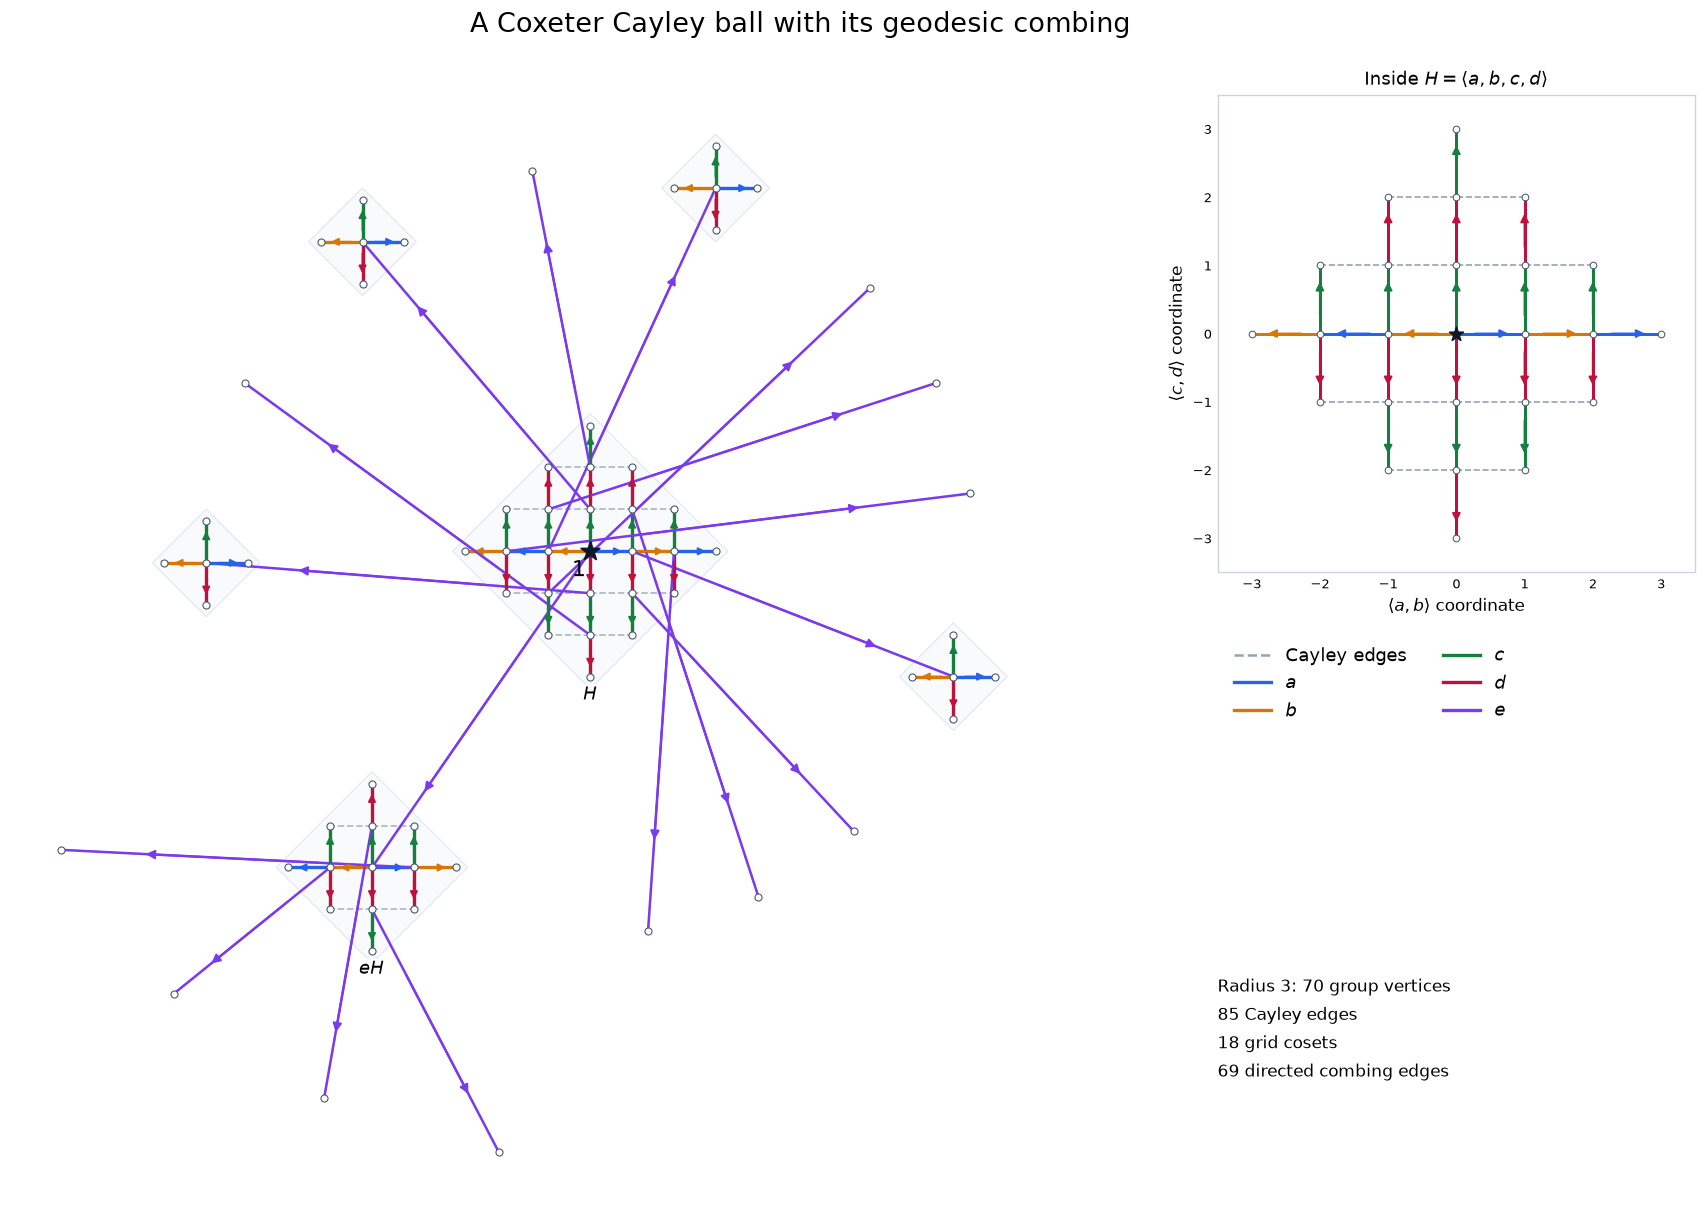

70 vertices; 85 Cayley edges; 69 combing edges; 18 grid cosets.


In [11]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Polygon, FancyArrowPatch

cayley_radius = 3
if not isinstance(cayley_radius, int) or cayley_radius < 1:
    raise ValueError('cayley_radius must be a positive integer.')

cayley_distance = {(): 0}
frontier = [()]
for depth in range(cayley_radius):
    next_frontier = []
    for g in frontier:
        for s in letters:
            h = cayley_multiply(g, s)
            if h not in cayley_distance:
                cayley_distance[h] = depth + 1
                next_frontier.append(h)
    frontier = next_frontier
cayley_ball = nx.Graph()
cayley_ball.add_nodes_from(cayley_distance)
for g in cayley_distance:
    for s in letters:
        h = cayley_multiply(g,s)
        if h in cayley_distance:
            cayley_ball.add_edge(g,h,generator=s)
combing_tree = nx.Graph()
combing_tree.add_nodes_from(cayley_ball)
for g in cayley_ball:
    assert len(g) == cayley_distance[g]
    if g:
        assert cayley_ball.has_edge(g[:-1],g)
        combing_tree.add_edge(g[:-1],g)
assert nx.is_tree(combing_tree)

# In the free-product normal form, remove the final H block to label gH.
def cayley_flat(g):
    return g[:len(g)-g[::-1].index('e')] if 'e' in g else ()

def dihedral_coordinate(word,pair):
    subword = tuple(s for s in word if s in pair)
    assert all(s != t for s,t in zip(subword,subword[1:]))
    return 0 if not subword else len(subword)*(1 if subword[0] == pair[0] else -1)

flat_vertices = {}
local_coordinates = {}
for g in cayley_ball:
    flat = cayley_flat(g)
    flat_vertices.setdefault(flat,[]).append(g)
    final_block = g[len(flat):]
    local_coordinates[g] = np.array([dihedral_coordinate(final_block,('a','b')),
                                     dihedral_coordinate(final_block,('c','d'))],dtype=float)
flat_tree = nx.Graph()
flat_tree.add_nodes_from(flat_vertices)
for g,h,data in cayley_ball.edges(data=True):
    if data['generator'] == 'e':
        assert cayley_flat(g) != cayley_flat(h)
        flat_tree.add_edge(cayley_flat(g),cayley_flat(h))
    else:
        assert cayley_flat(g) == cayley_flat(h)
        assert np.abs(local_coordinates[g]-local_coordinates[h]).sum() == 1
assert nx.is_tree(flat_tree)
assert sum(map(len,flat_vertices.values())) == len(cayley_ball)
assert all(len({tuple(local_coordinates[g]) for g in members}) == len(members)
           for members in flat_vertices.values())

# Allocate angular sectors to the coset tree while keeping each grid rigid.
flat_order = list(nx.bfs_tree(flat_tree,()))
flat_children = {f:[] for f in flat_order}
flat_level = {():0}
for parent,child in nx.bfs_edges(flat_tree,()):
    flat_children[parent].append(child)
    flat_level[child] = flat_level[parent]+1
grid_spacing = 0.60
flat_radius = {f:grid_spacing*max(np.abs(local_coordinates[g]).sum() for g in nodes)
               for f,nodes in flat_vertices.items()}
sector_weight = {}
for f in reversed(flat_order):
    flat_children[f].sort()
    sector_weight[f] = max(1+2*flat_radius[f],sum(sector_weight[ch] for ch in flat_children[f]))
flat_center = {():np.zeros(2)}
sector = {():(-np.pi/2,3*np.pi/2)}
base_ring = max(5.5,sector_weight[()]/(2*np.pi)*0.65)
for f in flat_order:
    low,high=sector[f]
    total=sum(sector_weight[ch] for ch in flat_children[f])
    cursor=low
    for ch in flat_children[f]:
        width=(high-low)*sector_weight[ch]/total
        sector[ch]=(cursor,cursor+width)
        angle=cursor+width/2
        ring=base_ring+3.2*(flat_level[ch]-1)
        flat_center[ch]=ring*np.array([np.cos(angle),np.sin(angle)])
        cursor+=width
cayley_pos={g:flat_center[cayley_flat(g)]+grid_spacing*local_coordinates[g] for g in cayley_ball}
letter_colors=dict(zip(letters,['#2563eb','#d97706','#15803d','#be123c','#7c3aed']))
cayley_gray='#94a3b8'
cone_red='#dc2626'

def add_combing_arrow(axis,g,h,positions,color,size=10):
    if cayley_distance[g]>cayley_distance[h]: g,h=h,g
    start=np.asarray(positions[g]); delta=np.asarray(positions[h])-start
    axis.add_patch(FancyArrowPatch(start+0.27*delta,start+0.76*delta,
        arrowstyle='-|>',mutation_scale=size,lw=1.2,color=color,shrinkA=0,shrinkB=0,zorder=5))

def draw_simple_cayley(mode='plain',highlight_word=()):
    if mode not in {'plain','combing','coned','path'}: raise ValueError('Unknown plot mode.')
    path_vertices=[()]
    if mode=='path':
        for s in highlight_word: path_vertices.append(cayley_multiply(path_vertices[-1],s))
        if any(g not in cayley_ball for g in path_vertices):
            raise ValueError('Increase cayley_radius and rerun Section 6 to include this word path.')
        assert all(cayley_ball.has_edge(g,h) for g,h in zip(path_vertices,path_vertices[1:]))
    fig=plt.figure(figsize=(15,10),constrained_layout=True)
    grid=fig.add_gridspec(2,2,width_ratios=[3.0,1.15],height_ratios=[1,1])
    ax=fig.add_subplot(grid[:,0]); detail=fig.add_subplot(grid[0,1]); note=fig.add_subplot(grid[1,1])
    note.axis('off')
    for flat,center in flat_center.items():
        extent=flat_radius[flat]
        if extent:
            hull=center+(extent+0.17)*np.array([(1,0),(0,1),(-1,0),(0,-1)])
            ax.add_patch(Polygon(hull,fc='#f8fafc',ec='#e2e8f0',lw=0.7,zorder=0))
    segments=[(cayley_pos[g],cayley_pos[h]) for g,h in cayley_ball.edges()]
    ax.add_collection(LineCollection(segments,colors=cayley_gray,linestyles='dashed',
                                     linewidths=1.05,alpha=0.75,zorder=1))
    if mode=='combing':
        for g,h in combing_tree.edges():
            s=cayley_ball[g][h]['generator']; points=np.array([cayley_pos[g],cayley_pos[h]])
            ax.plot(points[:,0],points[:,1],color=letter_colors[s],lw=1.5 if s=='e' else 2,zorder=3)
            add_combing_arrow(ax,g,h,cayley_pos,letter_colors[s],size=11 if s=='e' else 9)
    if mode=='coned':
        segments=[(cone_positions[flat],cayley_pos[g]) for flat,members in flat_vertices.items() for g in members]
        ax.add_collection(LineCollection(segments,colors=cone_red,lw=1,alpha=0.8,zorder=2))
        points=np.array(list(cone_positions.values()))
        ax.scatter(points[:,0],points[:,1],s=32,marker='D',facecolors=cone_red,edgecolors='white',lw=0.6,zorder=5)
    points=np.array(list(cayley_pos.values()))
    ax.scatter(points[:,0],points[:,1],s=18,facecolors='white',edgecolors='#475569',lw=0.65,zorder=6)
    ax.scatter([0],[0],s=140,marker='*',color='#0f172a',zorder=8)
    ax.annotate('$1$',(0,0),xytext=(-11,-15),textcoords='offset points',fontsize=13,zorder=9)
    for flat,label in [((),r'$H$'),(('e',),r'$eH$')]:
        center=flat_center[flat]
        ax.text(center[0],center[1]-flat_radius[flat]-0.33,label,ha='center',fontsize=11,
                bbox=dict(fc='white',ec='none',pad=1),zorder=8)
    if mode=='path':
        for s,g,h in zip(highlight_word,path_vertices,path_vertices[1:]):
            points=np.array([cayley_pos[g],cayley_pos[h]])
            ax.plot(points[:,0],points[:,1],color=letter_colors[s],lw=3,zorder=7)
            start,end=points; delta=end-start
            ax.add_patch(FancyArrowPatch(start+0.25*delta,start+0.75*delta,
                arrowstyle='-|>',mutation_scale=16,lw=2,color=letter_colors[s],zorder=8))
        for g,offset in zip(path_vertices[1:],[(8,-15),(8,-15),(8,8)]+[(8,8)]*len(highlight_word)):
            ax.annotate('$'+(''.join(g) if g else '1')+'$',cayley_pos[g],xytext=offset,
                textcoords='offset points',fontsize=11,zorder=10,
                bbox=dict(fc='white',ec='none',alpha=0.9,pad=1))
    # Common bounds leave room for every cone and label in all four pictures.
    all_points=np.array(list(cayley_pos.values())+
        [center+np.array([0,flat_radius[flat]+0.7]) for flat,center in flat_center.items()])
    ax.set(xlim=(all_points[:,0].min()-0.7,all_points[:,0].max()+0.7),
           ylim=(all_points[:,1].min()-0.7,all_points[:,1].max()+0.7),aspect='equal')
    ax.axis('off')

    # The root H coset has genuine integer lattice coordinates.
    root_vertices=flat_vertices[()]
    for g,h,data in cayley_ball.subgraph(root_vertices).edges(data=True):
        points=np.array([local_coordinates[g],local_coordinates[h]])
        colored=mode=='combing' and combing_tree.has_edge(g,h)
        detail.plot(points[:,0],points[:,1],color=letter_colors[data['generator']] if colored else cayley_gray,
                    lw=1.8 if colored else 1,ls='-' if colored else '--',zorder=1)
        if colored: add_combing_arrow(detail,g,h,local_coordinates,letter_colors[data['generator']],size=10)
    if mode=='coned':
        local_cone=(cone_positions[()]-flat_center[()])/grid_spacing
        for g in root_vertices:
            point=local_coordinates[g]
            detail.plot([local_cone[0],point[0]],[local_cone[1],point[1]],color=cone_red,lw=0.85,alpha=0.8,zorder=2)
        detail.scatter(*local_cone,color=cone_red,marker='D',s=45,zorder=6)
        detail.annotate('$v_H$',local_cone,xytext=(8,4),textcoords='offset points',fontsize=11,color=cone_red)
    if mode=='path':
        for s,g,h in zip(highlight_word,path_vertices,path_vertices[1:]):
            if g in root_vertices and h in root_vertices:
                points=np.array([local_coordinates[g],local_coordinates[h]])
                detail.plot(points[:,0],points[:,1],color=letter_colors[s],lw=2.6,zorder=3)
                start,end=points; delta=end-start
                detail.add_patch(FancyArrowPatch(start+0.2*delta,start+0.75*delta,
                    arrowstyle='-|>',mutation_scale=12,lw=1.8,color=letter_colors[s],zorder=5))
    points=np.array([local_coordinates[g] for g in root_vertices])
    detail.scatter(points[:,0],points[:,1],s=16,facecolors='white',edgecolors='#475569',lw=0.6,zorder=4)
    detail.scatter([0],[0],s=75,marker='*',color='#0f172a',zorder=6)
    detail.set(xlim=(-cayley_radius-0.5,cayley_radius+0.5),
               ylim=(-cayley_radius-0.5,cayley_radius+(1.6 if mode=='coned' else 0.5)),aspect='equal')
    detail.set_title(r'Inside $H=\langle a,b,c,d\rangle$',fontsize=11)
    detail.set_xlabel(r'$\langle a,b\rangle$ coordinate',fontsize=10)
    detail.set_ylabel(r'$\langle c,d\rangle$ coordinate',fontsize=10)
    detail.set_xticks(range(-cayley_radius,cayley_radius+1)); detail.set_yticks(range(-cayley_radius,cayley_radius+1))
    detail.tick_params(labelsize=8,length=0)
    for spine in detail.spines.values(): spine.set_color('#cbd5e1')
    handles=[Line2D([0],[0],color=cayley_gray,ls='--',label='Cayley edges')]
    if mode in {'combing','path'}:
        chosen=letters if mode=='combing' else tuple(dict.fromkeys(highlight_word))
        handles+=[Line2D([0],[0],color=letter_colors[s],lw=2,label='$'+s+'$') for s in chosen]
    if mode=='coned':
        handles+=[Line2D([0],[0],color=cone_red,lw=1.5,label='Cone edges'),
                  Line2D([0],[0],marker='D',color='none',markerfacecolor=cone_red,label='Cone vertices')]
    note.legend(handles=handles,loc='upper left',frameon=False,ncol=2 if mode=='combing' else 1)
    info=f'Radius {cayley_radius}: {len(cayley_ball)} group vertices\n{cayley_ball.number_of_edges()} Cayley edges\n{len(flat_vertices)} grid cosets'
    if mode=='combing': info+=f'\n{combing_tree.number_of_edges()} directed combing edges'
    if mode=='coned': info+=f'\n{len(flat_vertices)} cone vertices\n{len(cayley_ball)} cone edges'
    if mode=='path': info+='\nPath: 1 → '+' → '.join(''.join(highlight_word[:k]) for k in range(1,len(highlight_word)+1))
    note.text(0,0.4,info,transform=note.transAxes,fontsize=10,va='top',linespacing=1.7)
    titles={'combing':'A Coxeter Cayley ball with its geodesic combing',
            'coned':'The Coxeter Cayley ball coned off over $H$',
            'plain':'The Coxeter Cayley ball', 'path':'A directed word path in the Coxeter Cayley ball'}
    fig.suptitle(titles[mode],fontsize=16)
    return fig

fig_cayley_combing=draw_simple_cayley('combing')
fig_cayley_combing.savefig('simple_coxeter_cayley_combing.png',dpi=300,bbox_inches='tight')
plt.show()
print(f'{len(cayley_ball)} vertices; {cayley_ball.number_of_edges()} Cayley edges; '
      f'{combing_tree.number_of_edges()} combing edges; {len(flat_vertices)} grid cosets.')

## 7. Coning off the peripheral grid cosets

For every left coset $gH$ meeting the Cayley ball, add a red cone vertex and join it to every visible group vertex in that coset. All original Cayley edges remain dashed grey, and every group vertex has exactly one cone neighbor. Boundary cosets with only one visible vertex still get a cone.

This is a finite portion of the coned-off graph over the ordinary Cayley ball, not a ball in the coned-off metric. Cone positions are for visibility only. The inset shows the cone over the identity grid. Run Section 6 first; all four figures use identical group-vertex coordinates.

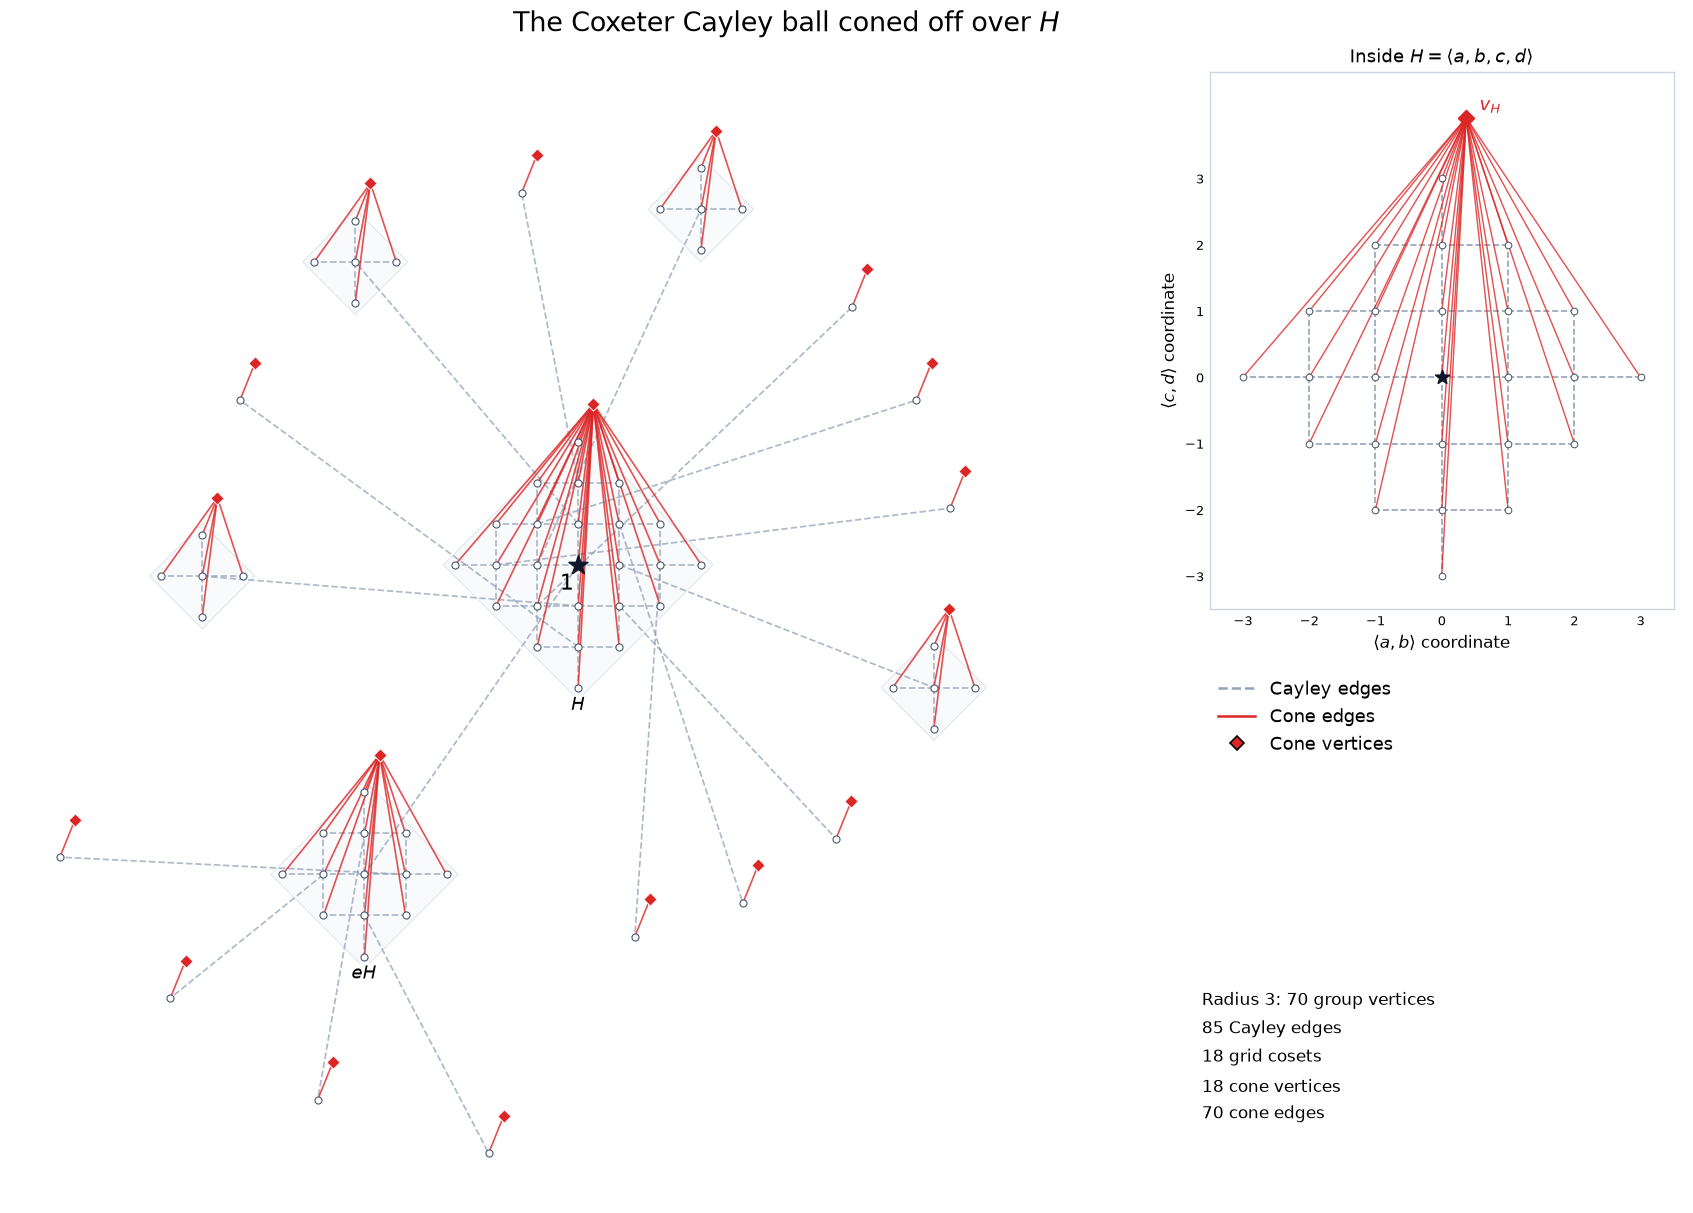

Added 18 cone vertices and 70 cone edges.


In [12]:
coned_ball=cayley_ball.copy()
nx.set_node_attributes(coned_ball,'group','kind')
nx.set_edge_attributes(coned_ball,'cayley','kind')
cone_vertices={flat:('cone',flat) for flat in flat_vertices}
cone_positions={flat:center+np.array([0.37*grid_spacing,flat_radius[flat]+0.55])
                for flat,center in flat_center.items()}
for flat,members in flat_vertices.items():
    cone=cone_vertices[flat]
    coned_ball.add_node(cone,kind='cone',coset=flat)
    coned_ball.add_edges_from((cone,g,{'kind':'cone'}) for g in members)
assert coned_ball.number_of_nodes()==len(cayley_ball)+len(flat_vertices)
assert coned_ball.number_of_edges()==cayley_ball.number_of_edges()+len(cayley_ball)
assert all(set(coned_ball.neighbors(cone_vertices[flat]))==set(members) for flat,members in flat_vertices.items())
assert all(sum(coned_ball.nodes[h]['kind']=='cone' for h in coned_ball[g])==1 for g in cayley_ball)
fig_coned=draw_simple_cayley('coned')
fig_coned.savefig('simple_coxeter_coned_cayley_ball.png',dpi=300,bbox_inches='tight')
plt.show()
print(f'Added {len(flat_vertices)} cone vertices and {len(cayley_ball)} cone edges.')

## 8. The Cayley graph alone, and a highlighted word path

The first figure shows the same Cayley ball with every edge dashed grey. The next cell highlights the path $1\to e\to ea\to eac$, using arrows along the three edges. This path first crosses an $e$-edge to a new grid coset, then moves in the two coordinate directions of that grid.

Change `highlight_word` to another word over $\{a,b,c,d,e\}$. If the path leaves the current ball, increase `cayley_radius` in Section 6 and rerun the plotting cells. The identity is denoted $1$ to distinguish it from generator $e$.

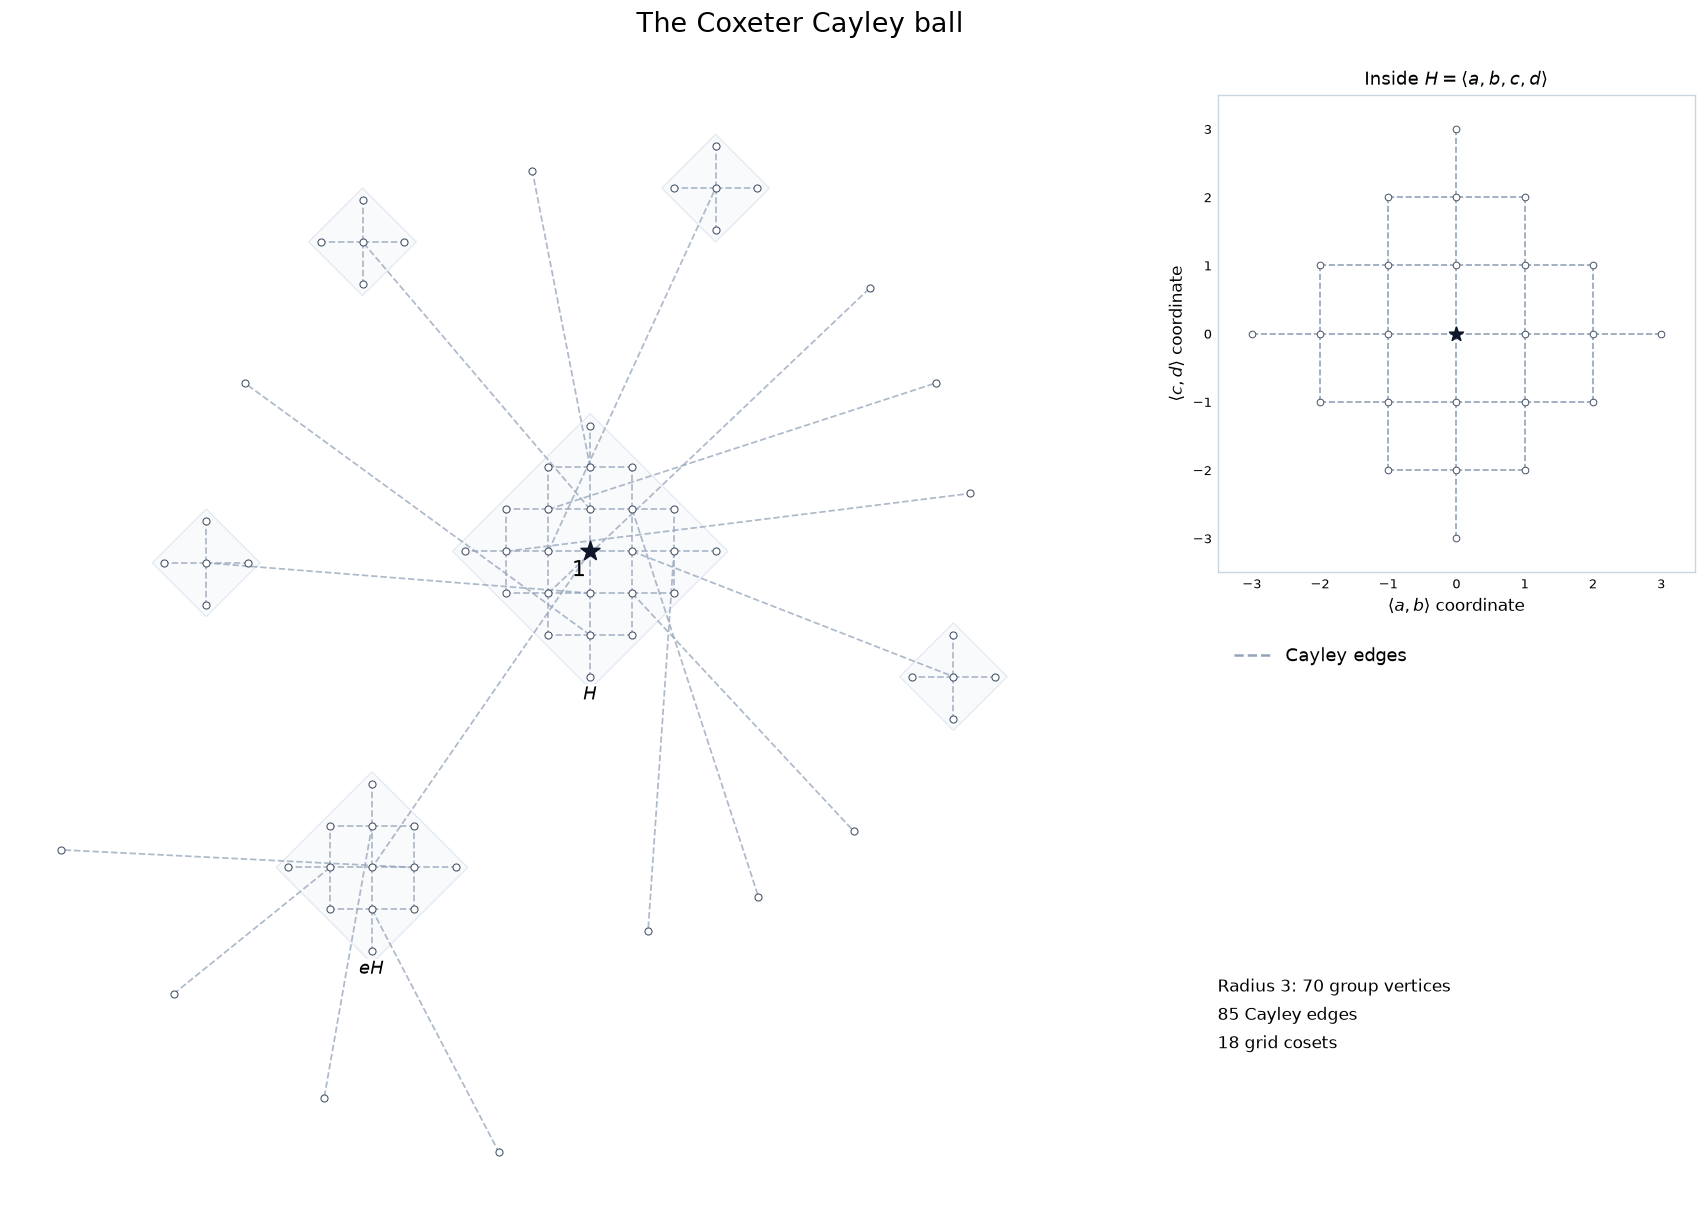

In [13]:
fig_cayley=draw_simple_cayley('plain')
fig_cayley.savefig('simple_coxeter_cayley_ball.png',dpi=300,bbox_inches='tight')
plt.show()

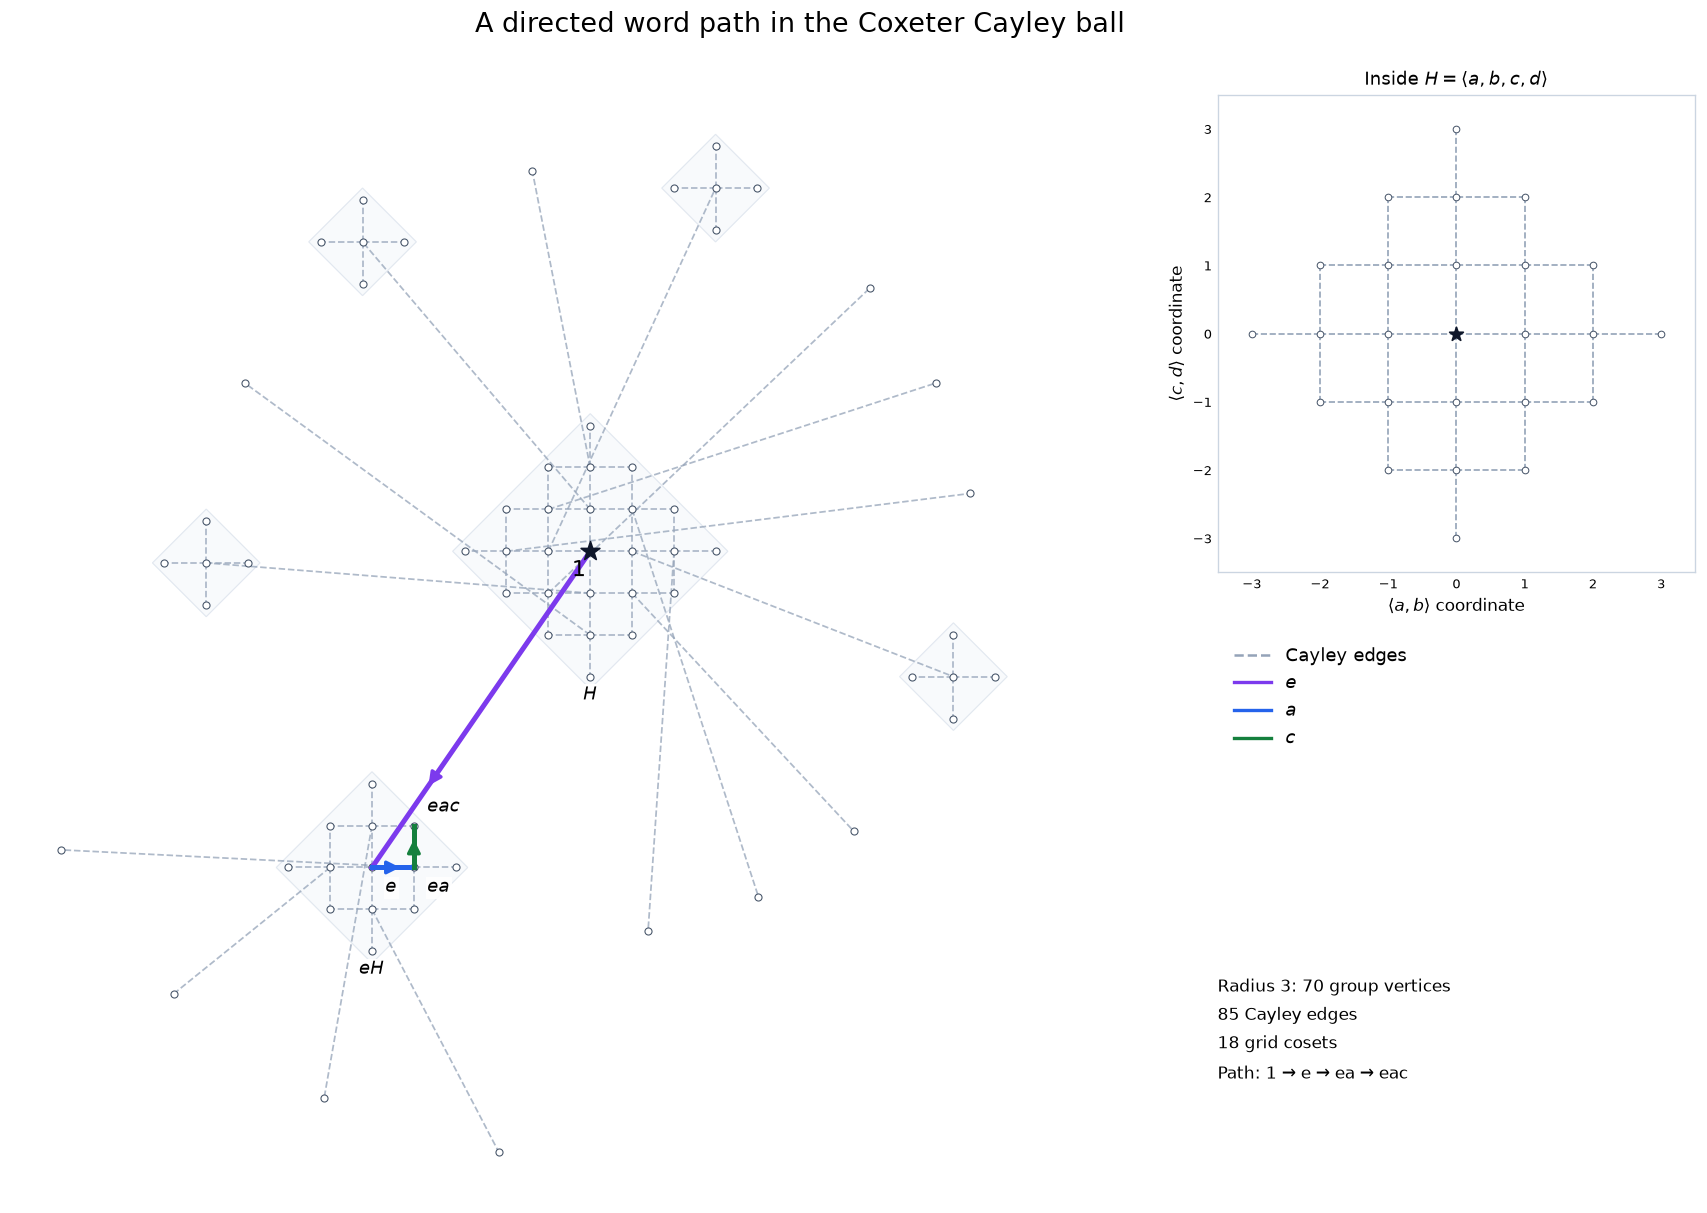

In [14]:
highlight_word=tuple('eac')
if any(s not in letters for s in highlight_word):
    raise ValueError(f'Use only the generators {letters}.')
fig_path=draw_simple_cayley('path',highlight_word=highlight_word)
fig_path.savefig('simple_coxeter_cayley_word_path.png',dpi=300,bbox_inches='tight')
plt.show()

## 9. Ordered frequencies along random geodesic paths

Sample one path from $v_0$ with the transition probabilities in $N$. For a target word $w$ of length $k$, examine consecutive **disjoint** blocks of $k$ letters. After $m$ complete blocks the ordered frequency is
$$F_w(m)=\frac{1}{m}\sum_{j=0}^{m-1}\mathbf1\{\sigma_{jk}\cdots\sigma_{(j+1)k-1}=w\}.$$
Discard a trailing incomplete block. The stationary limit is the exact cylinder probability
$$p_\mu(w)=\sum_x\mu_x\,\mathbb P_x(\text{next }k\text{ labels are }w).$$
The unique recurrent component is irreducible and aperiodic, so every $k$-step chain is ergodic and the ordered frequencies converge almost surely to these limits. The finite sample starts at $v_0$, not in stationarity.

All letters are involutions, including $e$; the identity element is written $1$. The word `aa` is not geodesic. The word `ca` is geodesic but is excluded from the combing because $ca=ac$ and the $a,b$ factor is written first. Both have zero stationary probability. Alternating words `ab`, `abab`, and `ababab` are geodesic and give increasingly rare targets.

Edit `path_length`, `seed`, and `target_words` below. The default sample has 100,000 letters. The exact table and both types of convergence plot use this same sample. Empty targets and unknown letters are rejected; if the sample has no complete block, the empirical frequency is undefined.


Combing automaton for reference:

<img src="simple_coxeter_automaton.png" width="650">


In [15]:
# Configuration: all targets are measured on the same seeded path.
path_length = 100_000
seed = 67
target_words = ['a', 'ac', 'ca', 'ab', 'abab', 'ababab']

from IPython.display import Markdown

frequency_next = {v: dict(outgoing) for v, outgoing in transitions.items()}
frequency_N = np.array(N, dtype=float)
assert np.all(frequency_N >= 0) and np.allclose(frequency_N.sum(axis=1), 1)


def random_geodesic_ray(n, seed=None, return_states=False):
    """Sample n edge labels from v0 using N; optionally return all n+1 states."""
    if not isinstance(n, (int, np.integer)) or n < 0:
        raise ValueError('n must be a nonnegative integer')
    rng = np.random.default_rng(seed)
    outgoing_probs = {v: np.array([frequency_N[idx[v], idx[t]] for _, t in transitions[v]])
                      for v in states}
    assert all(np.isclose(p.sum(), 1) for p in outgoing_probs.values())
    word, state_path, current = [], ['v0'], 'v0'
    for _ in range(n):
        choice = rng.choice(len(transitions[current]), p=outgoing_probs[current])
        letter, current = transitions[current][choice]
        word.append(letter)
        state_path.append(current)
    return (word, state_path) if return_states else word


def frequency_target(word):
    """Normalize a target over the generator alphabet; admissibility is separate."""
    word = tuple(word)
    if not word:
        raise ValueError('The target word must be nonempty')
    if any(s not in letters for s in word):
        raise ValueError(f'Unknown generator: use only {letters}')
    return word


def ordered_frequency(word_w, sigma):
    """Count aligned complete blocks; validate the sample against this automaton."""
    w, sample = frequency_target(word_w), tuple(sigma)
    current = 'v0'
    for i, s in enumerate(sample):
        if s not in frequency_next[current]:
            raise ValueError(f'Sample is not a combing path at position {i}: {current} --{s}--> ?')
        current = frequency_next[current][s]
    k = len(w)
    num_blocks = len(sample) // k
    count = sum(sample[j*k:(j+1)*k] == w for j in range(num_blocks))
    return {'count': count, 'num_blocks': num_blocks,
            'frequency': count / num_blocks if num_blocks else float('nan')}


def stationary_word_probability(word_w):
    """Exact stationary probability, summing all compatible starting vertices."""
    word = frequency_target(word_w)
    probability = sp.S.Zero
    for source in states:
        current, weight = source, mu[idx[source]]
        for s in word:
            target = frequency_next[current].get(s)
            if target is None:
                weight = sp.S.Zero
                break
            weight *= N[idx[current], idx[target]]
            current = target
        probability += weight
    return sp.simplify(probability)


sigma, sampled_state_path = random_geodesic_ray(path_length, seed=seed, return_states=True)
assert len(sampled_state_path) == len(sigma) + 1 and sampled_state_path[0] == 'v0'
assert all(frequency_next[u].get(s) == v
           for u, s, v in zip(sampled_state_path, sigma, sampled_state_path[1:]))

# Small checks distinguish disjoint blocks from overlapping windows.
assert ordered_frequency('ab', 'ababa') == {'count': 2, 'num_blocks': 2, 'frequency': 1.0}
assert ordered_frequency('ba', 'abab')['count'] == 0
assert stationary_word_probability('ca') == 0
assert stationary_word_probability('aa') == 0
assert sp.simplify(sum(stationary_word_probability(s) for s in letters)) == 1

frequency_results = []
for word in target_words:
    result = ordered_frequency(word, sigma)
    result.update(word=''.join(word), stationary_probability=stationary_word_probability(word))
    frequency_results.append(result)

print(f'N-weighted path from v0: {path_length:,} letters; seed={seed}.')
print('First 60 letters:', ''.join(sigma[:60]))
print('Exact stationary values are stored in frequency_results.')
rows = ['| Word | Count | Complete blocks | Empirical frequency | Stationary limit | Exact stationary limit |',
        '|:--|--:|--:|--:|--:|:--|']
for result in frequency_results:
    rows.append(f"| `{result['word']}` | {result['count']:,} | {result['num_blocks']:,} | "
                f"{result['frequency']:.6f} | {float(result['stationary_probability']):.6f} | "
                f"${sp.latex(result['stationary_probability'])}$ |")
display(Markdown('\n'.join(rows)))


N-weighted path from v0: 100,000 letters; seed=67.
First 60 letters: badcebacdeabedecebaceabdcecdceaeabcececdcdedeabeabcdcdedcdce
Exact stationary values are stored in frequency_results.


| Word | Count | Complete blocks | Empirical frequency | Stationary limit | Exact stationary limit |
|:--|--:|--:|--:|--:|:--|
| `a` | 16,689 | 100,000 | 0.166890 | 0.166667 | $\frac{1}{6}$ |
| `ac` | 1,381 | 50,000 | 0.027620 | 0.027778 | $\frac{1}{36}$ |
| `ca` | 0 | 50,000 | 0.000000 | 0.000000 | $0$ |
| `ab` | 2,801 | 50,000 | 0.056020 | 0.055556 | $\frac{1}{18}$ |
| `abab` | 145 | 25,000 | 0.005800 | 0.006173 | $\frac{1}{162}$ |
| `ababab` | 14 | 16,666 | 0.000840 | 0.000686 | $\frac{1}{1458}$ |

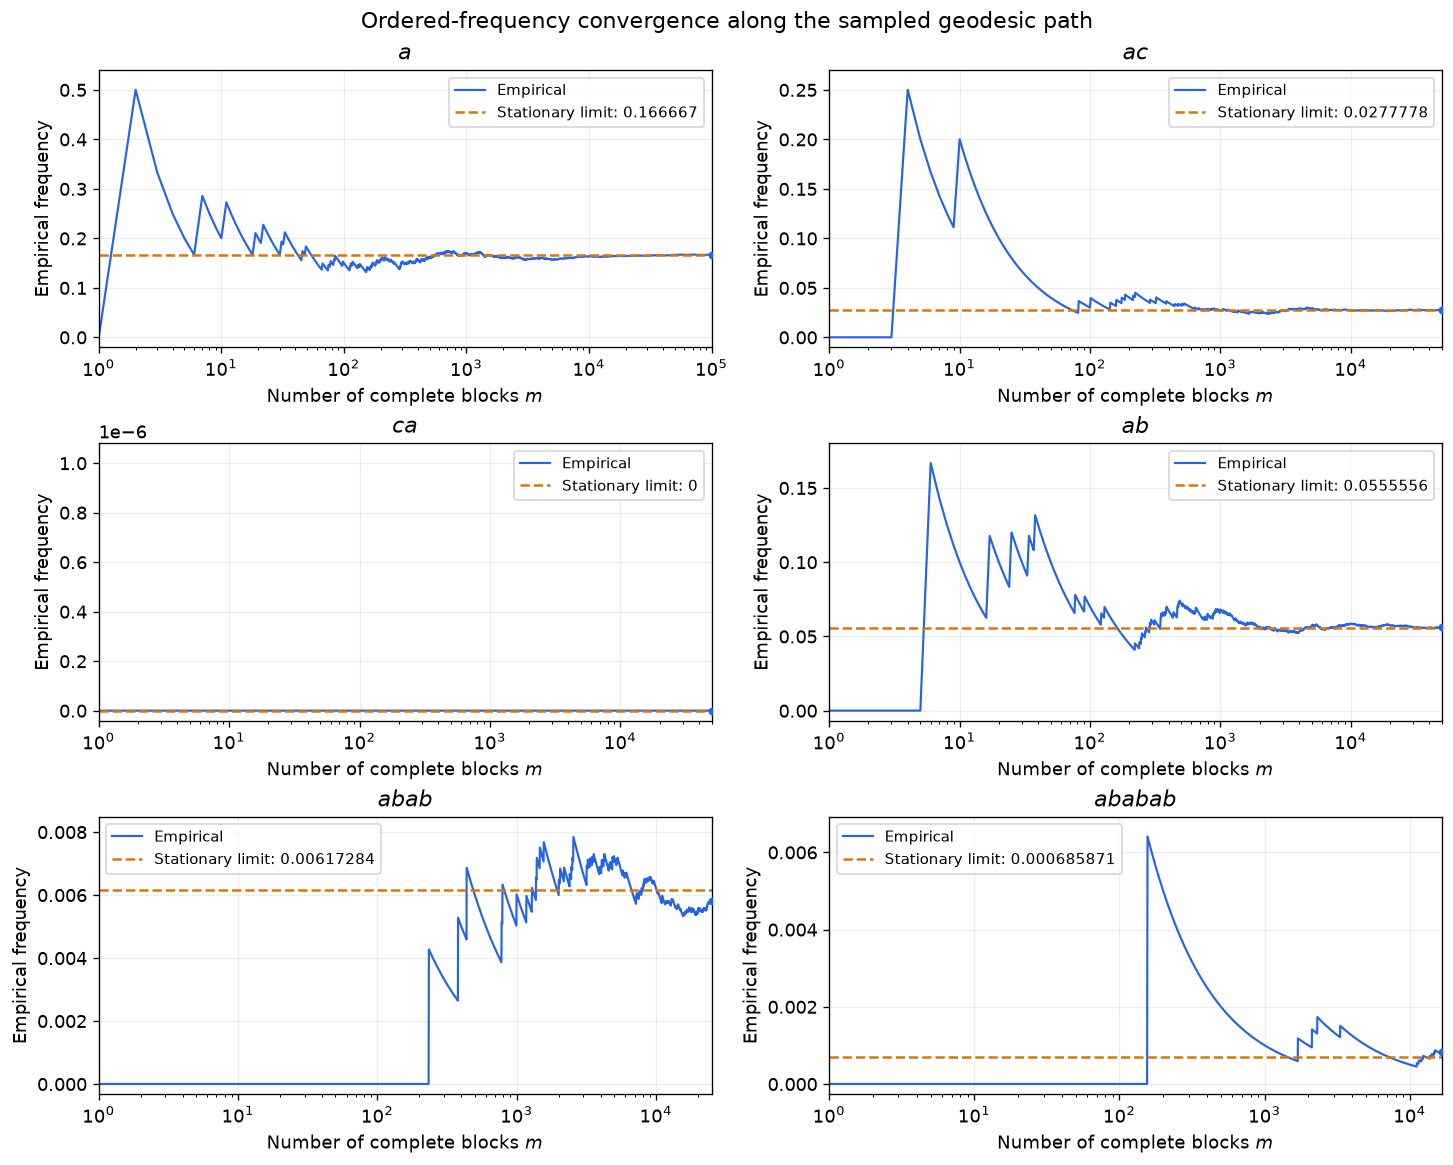

In [16]:
# Cumulative ordered frequencies on the SAME sampled path sigma from above.
# The horizontal axis counts complete, disjoint blocks of the target's length.
import numpy as np
import matplotlib.pyplot as plt

convergence_xscale = 'log'  # Change to 'linear' for equally spaced block counts.
convergence_max_points = 3000  # Plot fewer points on long paths; count every block.

if not target_words:
    raise ValueError('Set at least one target word in the preceding cell.')
if convergence_xscale not in {'log', 'linear'}:
    raise ValueError("convergence_xscale must be 'log' or 'linear'.")
if convergence_max_points < 2:
    raise ValueError('convergence_max_points must be at least 2.')

convergence_sample = np.asarray(sigma, dtype='U1')
convergence_columns = min(2, len(target_words))
convergence_rows = (len(target_words) + convergence_columns - 1) // convergence_columns
fig_frequency, frequency_axes = plt.subplots(
    convergence_rows, convergence_columns,
    figsize=(12, 3.2 * convergence_rows), squeeze=False, constrained_layout=True)
frequency_convergence = {}

for axis, target in zip(frequency_axes.flat, target_words):
    word = frequency_target(target)
    k = len(word)
    num_blocks = len(convergence_sample) // k
    limit = float(stationary_word_probability(word))
    axis.set_title('$' + ''.join(letter_tex[s].strip() for s in word) + '$')
    axis.set_xlabel('Number of complete blocks $m$')
    axis.set_ylabel('Empirical frequency')
    axis.set_xscale(convergence_xscale)
    axis.grid(True, alpha=0.22)

    if num_blocks:
        blocks = convergence_sample[:num_blocks*k].reshape(num_blocks, k)
        hits = np.all(blocks == np.asarray(word, dtype='U1'), axis=1)
        block_counts = np.arange(1, num_blocks + 1)
        cumulative_frequencies = np.cumsum(hits, dtype=np.int64) / block_counts
        # All frequencies are computed; only the drawing is downsampled.
        number_to_plot = min(num_blocks, convergence_max_points)
        spacing = np.geomspace if convergence_xscale == 'log' else np.linspace
        plot_indices = np.unique(spacing(1, num_blocks, number_to_plot).astype(int)) - 1
        axis.plot(block_counts[plot_indices], cumulative_frequencies[plot_indices],
                  color='#2563eb', lw=1.3, label='Empirical')
        axis.scatter([num_blocks], [cumulative_frequencies[-1]],
                     color='#2563eb', s=14, zorder=4)
        axis.axhline(limit, color='#d97706', ls='--', lw=1.5,
                     label=f'Stationary limit: {limit:.6g}')
        # Keep rare-word limits visible even when no occurrences were sampled.
        frequency_scale = max(float(cumulative_frequencies.max()), limit, 1e-6)
        axis.set_ylim(-0.04 * frequency_scale, 1.08 * frequency_scale)
        if num_blocks > 1:
            axis.set_xlim(1, num_blocks)
        frequency_convergence[''.join(word)] = {
            'blocks': block_counts, 'frequencies': cumulative_frequencies,
            'stationary_probability': limit}
        axis.legend(fontsize=9, loc='best')
    else:
        axis.text(0.5, 0.5, 'No complete blocks in this sample',
                  transform=axis.transAxes, ha='center', va='center')
        frequency_convergence[''.join(word)] = {
            'blocks': np.array([], dtype=int), 'frequencies': np.array([]),
            'stationary_probability': limit}

for axis in list(frequency_axes.flat)[len(target_words):]:
    axis.set_visible(False)
fig_frequency.suptitle('Ordered-frequency convergence along the sampled geodesic path')
fig_frequency.savefig('simple_coxeter_ordered_frequency_convergence.png', dpi=300, bbox_inches='tight')
plt.show()


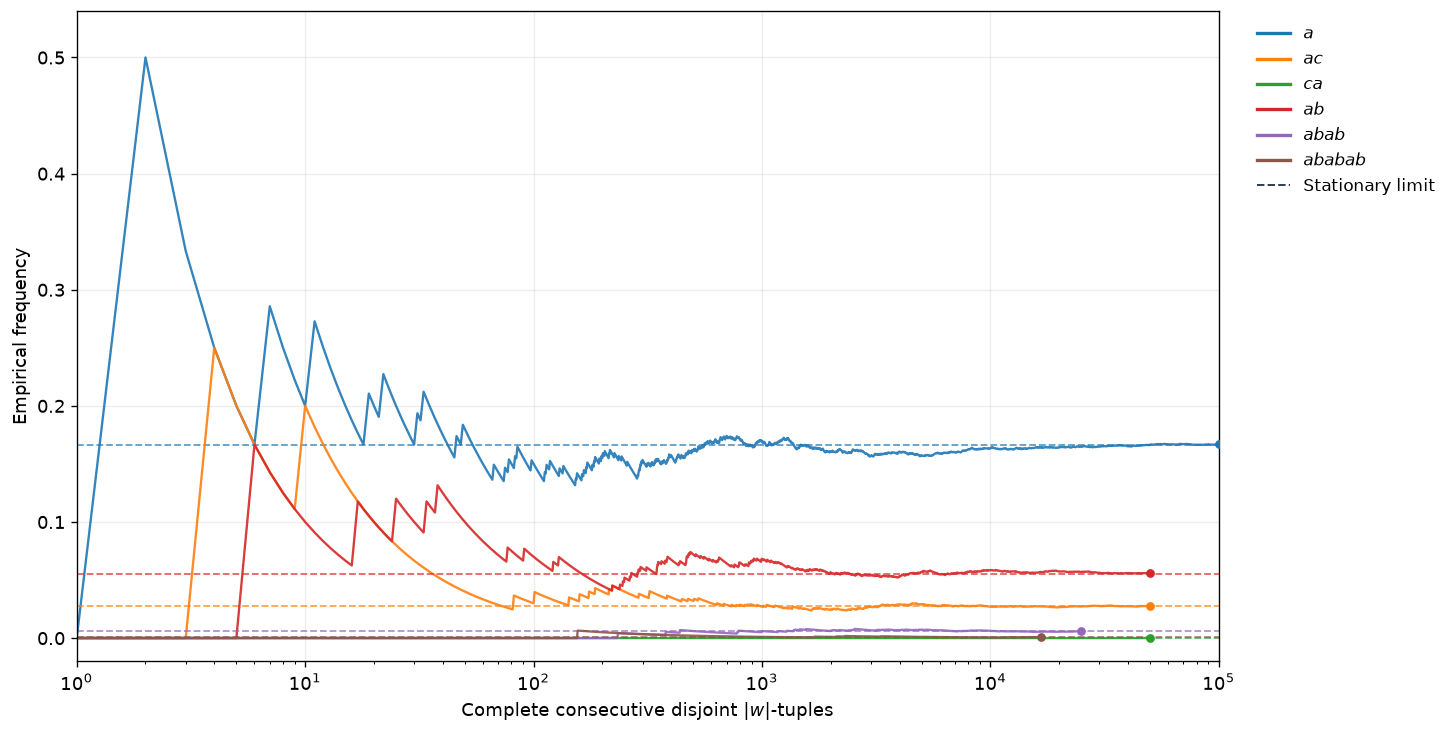

In [17]:
# Overlay the curves computed in the preceding cell; do not sample a new path.
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

fig_frequency_all, ax_frequency_all = plt.subplots(figsize=(12, 6), constrained_layout=True)
combined_colors = plt.get_cmap('tab10' if len(frequency_convergence) <= 10 else 'tab20')
combined_handles = []
combined_max_blocks = 0
combined_max_frequency = 0.0

for j, (word, curve) in enumerate(frequency_convergence.items()):
    counts = curve['blocks']
    empirical = curve['frequencies']
    limit = curve['stationary_probability']
    color = combined_colors(j % combined_colors.N)
    label = '$' + ''.join(letter_tex[s].strip() for s in word) + '$'
    combined_handles.append(Line2D([0], [0], color=color, lw=2, label=label))
    if len(counts):
        number_to_plot = min(len(counts), convergence_max_points)
        spacing = np.geomspace if convergence_xscale == 'log' else np.linspace
        selected = np.unique(spacing(1, len(counts), number_to_plot).astype(int)) - 1
        ax_frequency_all.plot(counts[selected], empirical[selected],
                               color=color, lw=1.4, alpha=0.9)
        ax_frequency_all.scatter(counts[-1], empirical[-1], color=color, s=18, zorder=4)
        combined_max_blocks = max(combined_max_blocks, int(counts[-1]))
        combined_max_frequency = max(combined_max_frequency, float(empirical.max()))
    ax_frequency_all.axhline(limit, color=color, ls='--', lw=1.1, alpha=0.7)
    combined_max_frequency = max(combined_max_frequency, limit)

combined_handles.extend([
    # Line2D([0], [0], color='#334155', lw=1.5, label='Empirical frequency'),
    Line2D([0], [0], color='#334155', lw=1.2, ls='--', label='Stationary limit')])
ax_frequency_all.legend(handles=combined_handles, loc='upper left',
                         bbox_to_anchor=(1.02, 1), frameon=False, fontsize=10)
ax_frequency_all.set_xscale(convergence_xscale)
if combined_max_blocks > 1:
    ax_frequency_all.set_xlim(1, combined_max_blocks)
ax_frequency_all.set_yscale('linear')
combined_scale = max(combined_max_frequency, 1e-6)
ax_frequency_all.set_ylim(-0.04 * combined_scale, 1.08 * combined_scale)
ax_frequency_all.set_xlabel('Complete consecutive disjoint $|w|$-tuples')
ax_frequency_all.set_ylabel('Empirical frequency')
# ax_frequency_all.set_title('Ordered-frequency convergence: all target words')
ax_frequency_all.grid(True, alpha=0.22)
fig_frequency_all.savefig('simple_coxeter_ordered_frequency_convergence_combined.png',
                           dpi=300, bbox_inches='tight')
plt.show()


## References and conventions

- This example uses the reduced-word theorem for free products and the alternating normal forms in $D_\infty=C_2*C_2$. A square commutation graph defines $D_\infty\times D_\infty$, and adding an isolated vertex gives its free product with $C_2$.
- Caprace, *Buildings with isolated subspaces and relatively hyperbolic Coxeter groups* (2009): the relative-hyperbolic Coxeter setting and virtually abelian peripherals. [Paper](https://msp.org/iig/2009/10-1/iig-v10-n1-p02-s.pdf). For this particular free product, relative hyperbolicity with respect to $H$ can also be seen from its Bass–Serre tree, whose infinite vertex stabilizers are conjugates of $H$ and whose edge stabilizers are trivial.
- Munro–Osajda–Przytycki, *2-dimensional Coxeter groups are biautomatic*, Theorem 1.1: existence of a geodesic biautomatic language over the natural Coxeter generators. [arXiv:2006.07947](https://arxiv.org/abs/2006.07947). Our square-plus-isolated-vertex graph is triangle-free and hence defines a 2-dimensional Coxeter group. Thus this generating set is admissible in the manuscript's sense; this statement does not require identifying the theorem's language with our chosen combing.
- Exact Perron–Frobenius normalization follows [the manuscript's geodesic-combing section](../ordered_frequency_git/sections/geodesic_combings.tex); aligned disjoint-block frequencies follow [its ordered-frequency section](../ordered_frequency_git/sections/ordered_frequency.tex).

Edges in the defining graph mean **commutation**, not the usual Coxeter-diagram convention. Every generator is its own inverse. The peripheral group $H$ is virtually abelian, not abelian: its translation subgroup $\langle ab,cd\rangle\cong\mathbb Z^2$ has index four. The group $W$ is non-elementary relatively hyperbolic and is not word-hyperbolic because it contains $\mathbb Z^2$.

All figure cells save PNGs beside this notebook. The coned-off finite ball is an illustration of the infinite relative Cayley graph, not itself the object used to define relative hyperbolicity.
